# Lab Task #05 – Spatial Filtering and Convolution

**The University of Azad Jammu and Kashmir**  
**Department of Software Engineering**  
**Digital Image Processing Lab**  
**Lab Instructor:** Engr. Fahad Nisar  
**Semester:** Fifth | **Session:** 2024–28 (SE)

**Student Name:** Maryam Shaheen  
**Roll Number:** 2024-SE-30  

## Objective
Implement two-dimensional convolution from first principles and apply mean, Gaussian, and median filters to remove Gaussian and salt-and-pepper noise from the `camera`, `coins`, and `chelsea` test images. Verify the custom convolution against OpenCV and compare filtered results with the clean originals.

## Required libraries
Python 3, NumPy, OpenCV, Matplotlib, and scikit-image.

In [18]:
!pip install opencv-python

In [19]:
# 1. Import libraries
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)

NumPy: 2.4.6
OpenCV: 5.0.0


## 2. Load the three test images
The original images are kept unchanged. The `chelsea` RGB image is converted to grayscale; all images are represented as 8-bit grayscale arrays.

camera shape = (512, 512) dtype = uint8 range = (np.uint8(0), np.uint8(255))
coins shape = (303, 384) dtype = uint8 range = (np.uint8(1), np.uint8(252))
chelsea shape = (300, 451) dtype = uint8 range = (np.uint8(4), np.uint8(194))


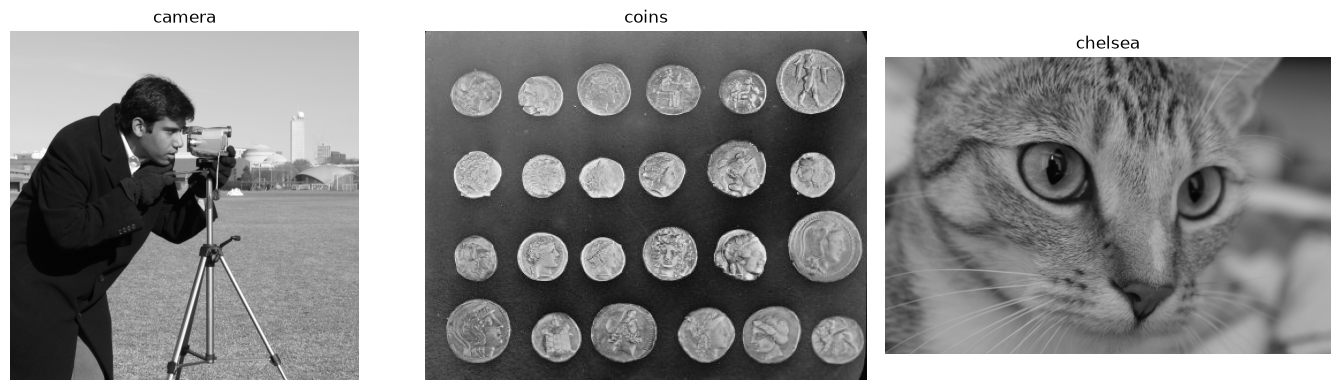

In [20]:
camera = data.camera()
coins = data.coins()
chelsea_rgb = data.chelsea()
chelsea = cv2.cvtColor(chelsea_rgb, cv2.COLOR_RGB2GRAY)

originals = {
    "camera": camera.copy(),
    "coins": coins.copy(),
    "chelsea": chelsea.copy()
}

for name, img in originals.items():
    print(name, "shape =", img.shape, "dtype =", img.dtype, "range =", (img.min(), img.max()))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, img) in zip(axes, originals.items()):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Custom 2D convolution (`conv2d_loop`)
The kernel is flipped horizontally and vertically to perform true convolution. The image is padded with NumPy `reflect` padding. Calculation is performed in `float64`, and the returned array has the same height and width as the input.

In [21]:
def conv2d_loop(img, kernel):
    img = np.asarray(img, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)

    if img.ndim != 2 or kernel.ndim != 2:
        raise ValueError("Image and kernel must be 2D arrays.")
    if kernel.shape[0] % 2 == 0 or kernel.shape[1] % 2 == 0:
        raise ValueError("Kernel dimensions must be odd.")

    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2
    flipped_kernel = np.flip(kernel, axis=(0, 1))
    padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode="reflect")
    output = np.zeros(img.shape, dtype=np.float64)

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            region = padded[i:i+kh, j:j+kw]
            output[i, j] = np.sum(region * flipped_kernel)

    return output

def to_uint8(img):
    return np.clip(np.rint(img), 0, 255).astype(np.uint8)

print("Custom convolution function is ready.")

Custom convolution function is ready.


## 4. Verify custom convolution against OpenCV
OpenCV's `filter2D` performs correlation, so the kernel is flipped before passing it to OpenCV to match true convolution. `BORDER_REFLECT_101` matches NumPy's `reflect` padding.

In [22]:
# An asymmetric kernel makes the kernel-flip verification meaningful.
test_kernel = np.array([[1, 2, 0],
                        [0, 1, 0],
                        [-1, 0, 2]], dtype=np.float64)
test_img = originals["camera"].astype(np.float64)

custom_result = conv2d_loop(test_img, test_kernel)
opencv_result = cv2.filter2D(
    test_img, ddepth=cv2.CV_64F,
    kernel=np.flip(test_kernel, axis=(0, 1)),
    borderType=cv2.BORDER_REFLECT_101
)

largest_difference = np.max(np.abs(custom_result - opencv_result))
print("Largest absolute difference:", largest_difference)
print("Agreement within numerical tolerance:", np.allclose(custom_result, opencv_result, atol=1e-8))

Largest absolute difference: 0.0
Agreement within numerical tolerance: True


## 5. Add reproducible noise
Both noise functions use `seed=5`. Salt-and-pepper `amount` is the approximate fraction of image pixels changed in total, split equally between pepper and salt.

In [23]:
def add_gaussian_noise(img, sigma=20, seed=5):
    rng = np.random.default_rng(seed)
    noisy = np.asarray(img, dtype=np.float64) + rng.normal(0, sigma, np.asarray(img).shape)
    return to_uint8(noisy)

def add_salt_pepper(img, amount=0.05, seed=5):
    if not 0 <= amount <= 1:
        raise ValueError("amount must be between 0 and 1.")
    rng = np.random.default_rng(seed)
    noisy = np.asarray(img, dtype=np.uint8).copy()
    total = int(round(amount * noisy.size))
    pepper_count = total // 2
    salt_count = total - pepper_count
    indices = rng.permutation(noisy.size)
    flat = noisy.ravel()
    flat[indices[:pepper_count]] = 0
    flat[indices[pepper_count:pepper_count + salt_count]] = 255
    return noisy

noisy_images = {}
for name, img in originals.items():
    noisy_images[(name, "Gaussian noise")] = add_gaussian_noise(img, sigma=20, seed=5)
    noisy_images[(name, "Salt-and-pepper noise")] = add_salt_pepper(img, amount=0.05, seed=5)

# Reproducibility check: fresh calls with the same seed must be identical.
for name, img in originals.items():
    g1 = add_gaussian_noise(img, sigma=20, seed=5)
    g2 = add_gaussian_noise(img, sigma=20, seed=5)
    sp1 = add_salt_pepper(img, amount=0.05, seed=5)
    sp2 = add_salt_pepper(img, amount=0.05, seed=5)
    print(name, "Gaussian identical:", np.array_equal(g1, g2),
          "| Salt-pepper identical:", np.array_equal(sp1, sp2))

camera Gaussian identical: True | Salt-pepper identical: True
coins Gaussian identical: True | Salt-pepper identical: True
chelsea Gaussian identical: True | Salt-pepper identical: True


## 6. Display original and noisy images
This grid shows each clean original beside its Gaussian-noise and salt-and-pepper versions.

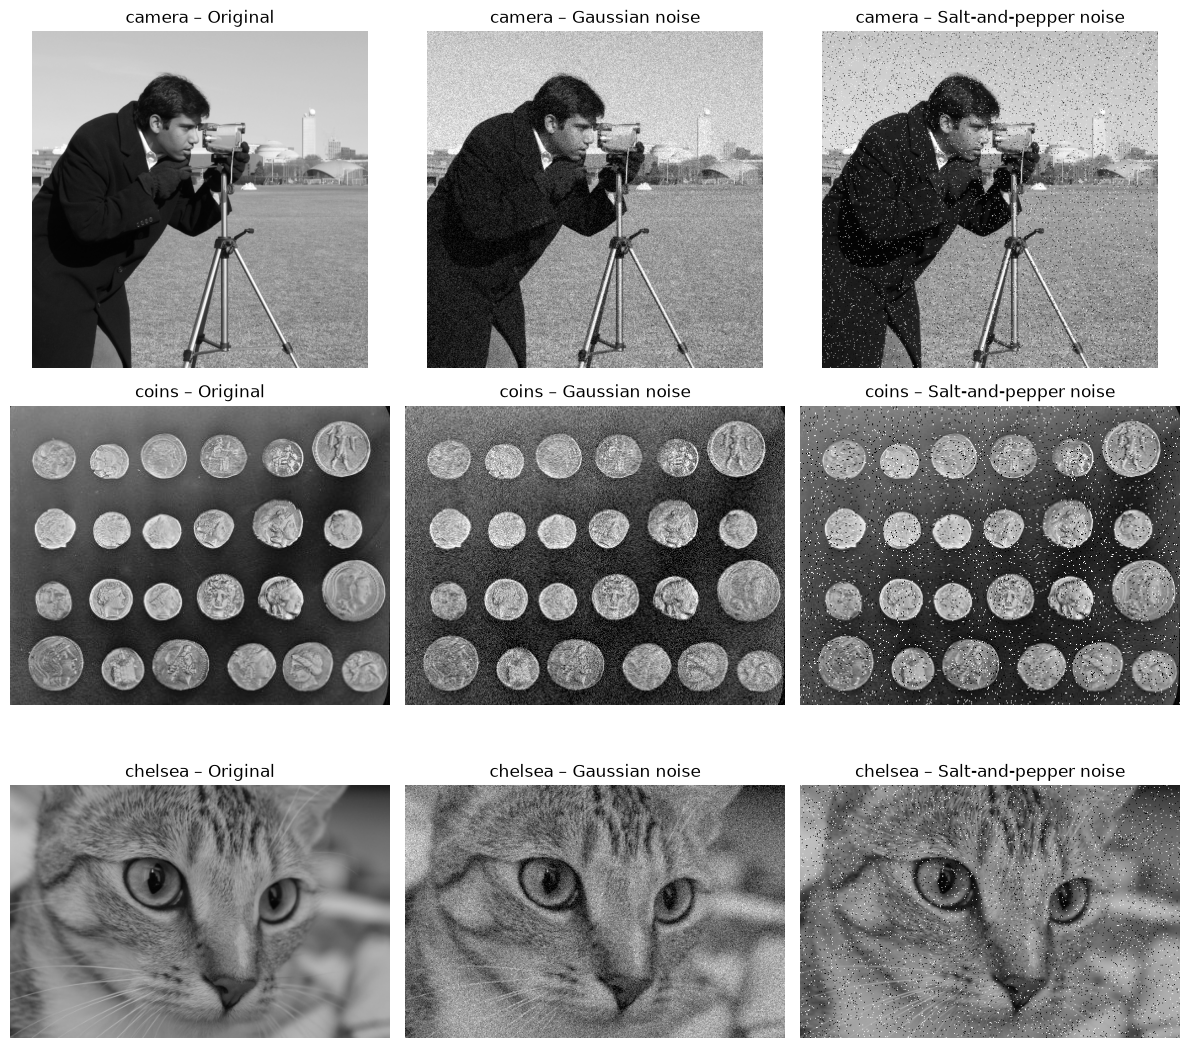

In [24]:
fig, axes = plt.subplots(3, 3, figsize=(12, 11))
for row, (name, img) in enumerate(originals.items()):
    items = [
        ("Original", img),
        ("Gaussian noise", noisy_images[(name, "Gaussian noise")]),
        ("Salt-and-pepper noise", noisy_images[(name, "Salt-and-pepper noise")])
    ]
    for col, (label, shown) in enumerate(items):
        axes[row, col].imshow(shown, cmap="gray", vmin=0, vmax=255)
        axes[row, col].set_title(f"{name} – {label}")
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

## 7. Create mean, Gaussian, and median filters
All kernel sizes are odd: 3, 5, and 7. Mean and Gaussian kernels are normalized so their weights sum to 1. Median filtering uses the middle sorted neighbourhood value.

In [25]:
def mean_kernel(size):
    if size not in (3, 5, 7):
        raise ValueError("Kernel size must be 3, 5, or 7.")
    return np.ones((size, size), dtype=np.float64) / (size * size)

def gaussian_kernel(size):
    if size not in (3, 5, 7):
        raise ValueError("Kernel size must be 3, 5, or 7.")
    one_d = cv2.getGaussianKernel(size, 0, cv2.CV_64F)
    kernel = one_d @ one_d.T
    return kernel / kernel.sum()

def apply_mean(img, size=3):
    kernel = mean_kernel(size)
    custom = conv2d_loop(img, kernel)
    # cv2.blur is used for the required OpenCV comparison.
    fast = cv2.blur(np.asarray(img, dtype=np.float64), (size, size),
                    borderType=cv2.BORDER_REFLECT_101)
    return to_uint8(custom), to_uint8(fast)

def apply_gaussian(img, size=3):
    kernel = gaussian_kernel(size)
    filtered = cv2.filter2D(np.asarray(img, dtype=np.float64), cv2.CV_64F,
                            kernel, borderType=cv2.BORDER_REFLECT_101)
    return to_uint8(filtered)

def apply_median(img, size=3):
    if size not in (3, 5, 7):
        raise ValueError("Median kernel size must be odd: 3, 5, or 7.")
    return cv2.medianBlur(np.asarray(img, dtype=np.uint8), size)

for size in (3, 5, 7):
    mk = mean_kernel(size)
    gk = gaussian_kernel(size)
    print(f"{size}x{size}: mean sum={mk.sum():.12f}, Gaussian sum={gk.sum():.12f}")

3x3: mean sum=1.000000000000, Gaussian sum=1.000000000000
5x5: mean sum=1.000000000000, Gaussian sum=1.000000000000
7x7: mean sum=1.000000000000, Gaussian sum=1.000000000000


## 8. Mean filter: custom convolution and OpenCV comparison
The custom mean-filter output and `cv2.blur` output should agree within rounding.

In [26]:
sample = noisy_images[("camera", "Gaussian noise")]
for size in (3, 5, 7):
    custom_mean, cv_mean = apply_mean(sample, size)
    print(f"{size}x{size} mean: maximum uint8 difference =",
          np.max(np.abs(custom_mean.astype(np.int16) - cv_mean.astype(np.int16))))

3x3 mean: maximum uint8 difference = 0
5x5 mean: maximum uint8 difference = 0
7x7 mean: maximum uint8 difference = 0


## 9. Apply all three 3×3 filters to every noisy image
Each filtered result is compared with the clean original image, not with the noisy image.

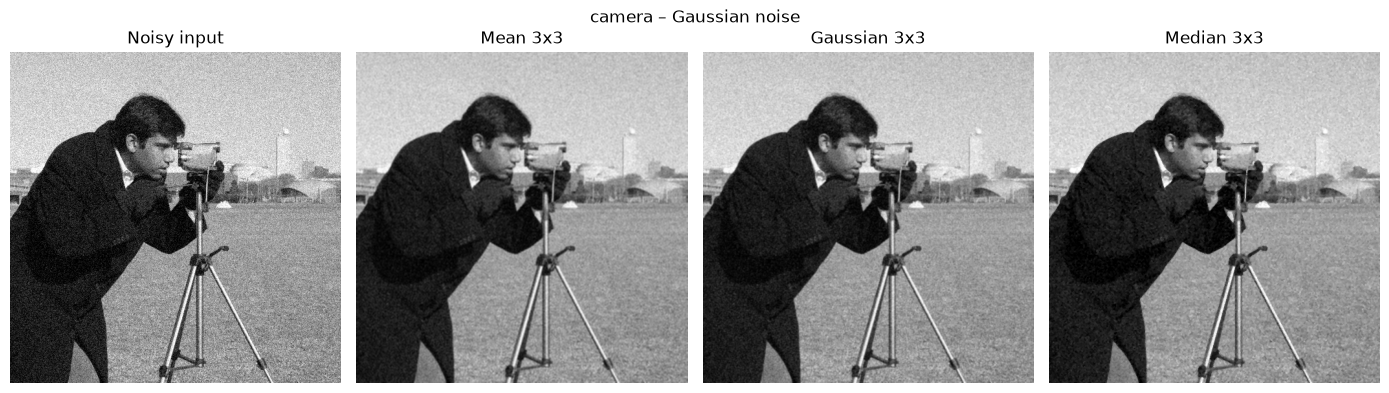

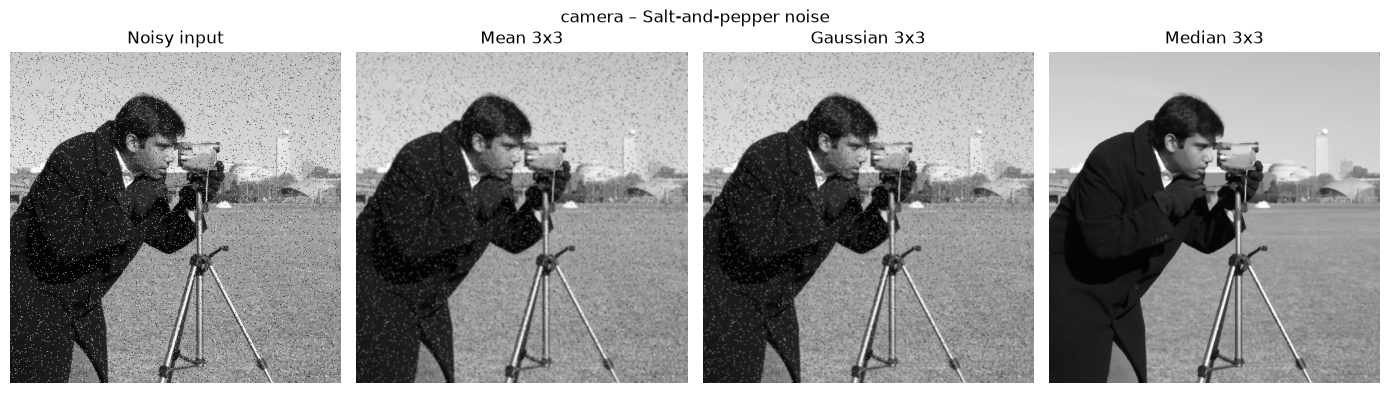

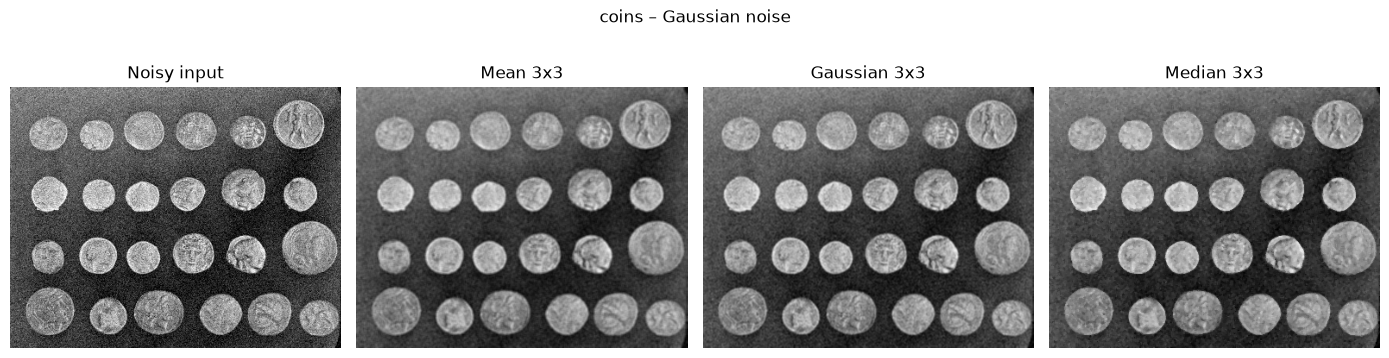

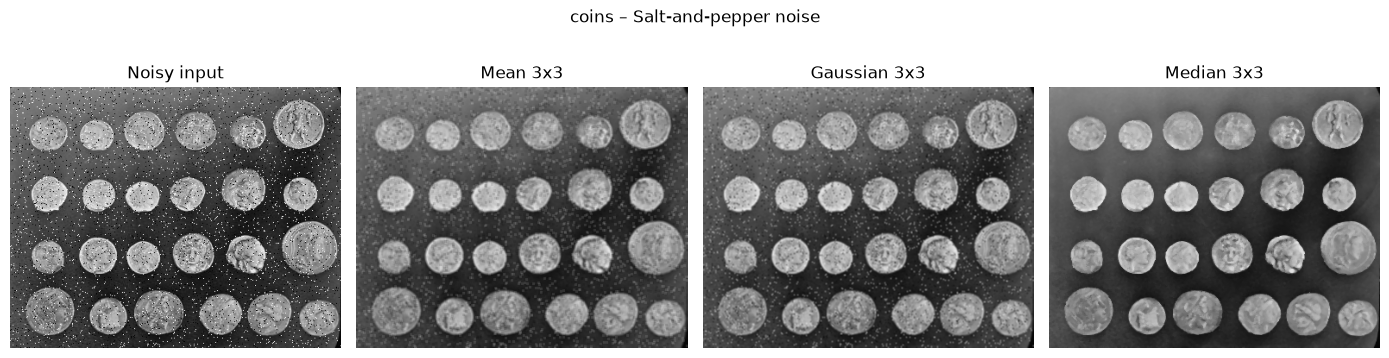

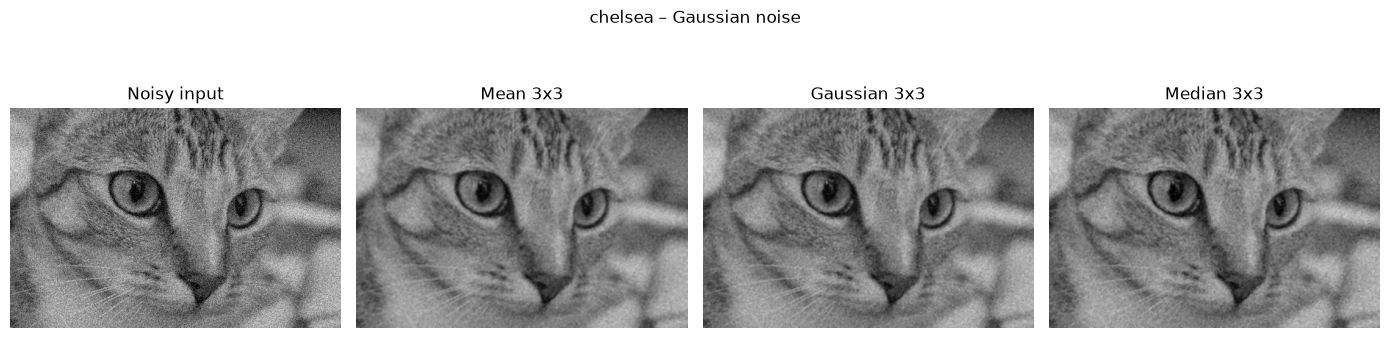

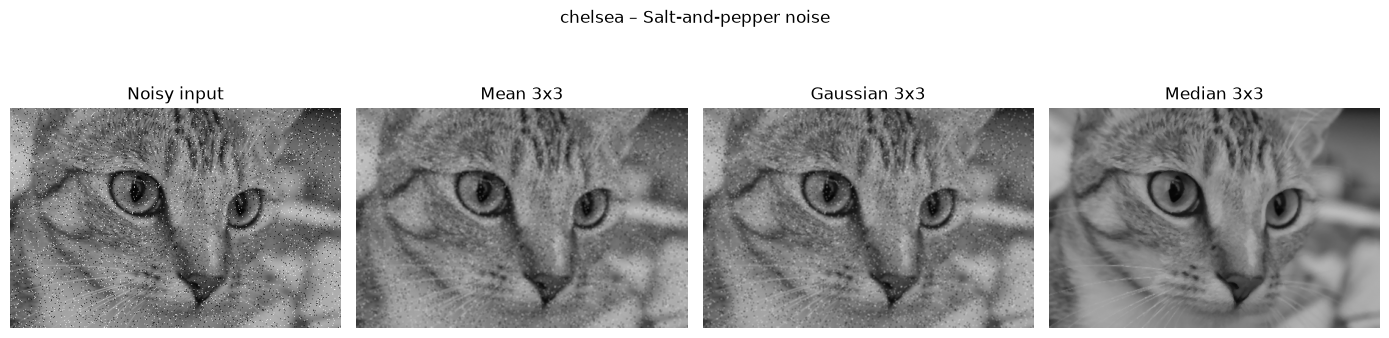

In [27]:
filtered_3x3 = {}
for name, clean in originals.items():
    for noise_name in ("Gaussian noise", "Salt-and-pepper noise"):
        noisy = noisy_images[(name, noise_name)]
        mean_img, _ = apply_mean(noisy, 3)
        filtered_3x3[(name, noise_name, "Mean")] = mean_img
        filtered_3x3[(name, noise_name, "Gaussian")] = apply_gaussian(noisy, 3)
        filtered_3x3[(name, noise_name, "Median")] = apply_median(noisy, 3)

# One labeled comparison grid for each original image and noise type.
for name, clean in originals.items():
    for noise_name in ("Gaussian noise", "Salt-and-pepper noise"):
        noisy = noisy_images[(name, noise_name)]
        fig, axes = plt.subplots(1, 4, figsize=(14, 4))
        display_items = [
            ("Noisy input", noisy),
            ("Mean 3x3", filtered_3x3[(name, noise_name, "Mean")]),
            ("Gaussian 3x3", filtered_3x3[(name, noise_name, "Gaussian")]),
            ("Median 3x3", filtered_3x3[(name, noise_name, "Median")])
        ]
        for ax, (label, shown) in zip(axes, display_items):
            ax.imshow(shown, cmap="gray", vmin=0, vmax=255)
            ax.set_title(label)
            ax.axis("off")
        fig.suptitle(f"{name} – {noise_name}")
        plt.tight_layout()
        plt.show()

## 10. Compare kernel sizes 3×3, 5×5, and 7×7
The notebook identifies the noisy test image with the largest mean-squared error (MSE) relative to its clean original. It then displays the nine combinations of filter type and kernel size for that image.

Selected noisiest case: ('camera', 'Salt-and-pepper noise') | MSE: 1078.107608795166


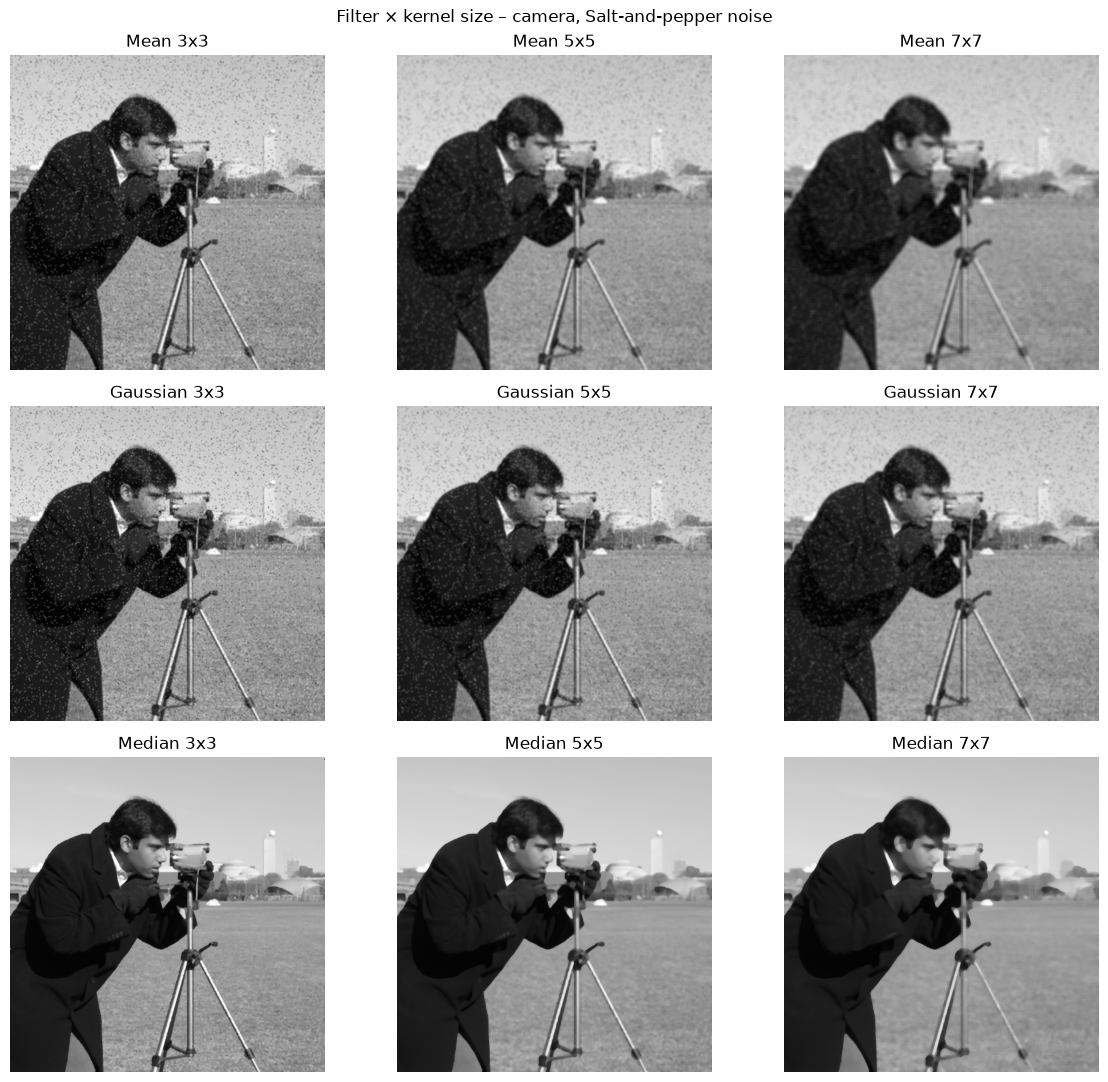

In [28]:
# Select the noisiest test case by its MSE against the corresponding clean original.
noise_scores = {}
for (name, noise_name), noisy in noisy_images.items():
    clean = originals[name].astype(np.float64)
    noise_scores[(name, noise_name)] = np.mean((noisy.astype(np.float64) - clean) ** 2)

noisiest_case = max(noise_scores, key=noise_scores.get)
noisy_name, noisy_type = noisiest_case
noisy_input = noisy_images[noisiest_case]
clean_reference = originals[noisy_name]
print("Selected noisiest case:", noisiest_case, "| MSE:", noise_scores[noisiest_case])

fig, axes = plt.subplots(3, 3, figsize=(12, 11))
for row, filter_name in enumerate(("Mean", "Gaussian", "Median")):
    for col, size in enumerate((3, 5, 7)):
        if filter_name == "Mean":
            result, _ = apply_mean(noisy_input, size)
        elif filter_name == "Gaussian":
            result = apply_gaussian(noisy_input, size)
        else:
            result = apply_median(noisy_input, size)
        axes[row, col].imshow(result, cmap="gray", vmin=0, vmax=255)
        axes[row, col].set_title(f"{filter_name} {size}x{size}")
        axes[row, col].axis("off")
plt.suptitle(f"Filter × kernel size – {noisy_name}, {noisy_type}")
plt.tight_layout()
plt.show()

## 11. Rule-compliance checks
Every displayed filter output must be `uint8`, remain in the range 0–255, and have the same shape as its input. An even median kernel size must be rejected.

In [29]:
# Check representative outputs from every filter size and image.
for name, clean in originals.items():
    for noise_name in ("Gaussian noise", "Salt-and-pepper noise"):
        noisy = noisy_images[(name, noise_name)]
        for size in (3, 5, 7):
            mean_out, _ = apply_mean(noisy, size)
            gaussian_out = apply_gaussian(noisy, size)
            median_out = apply_median(noisy, size)
            for label, out in (("Mean", mean_out), ("Gaussian", gaussian_out), ("Median", median_out)):
                assert out.dtype == np.uint8
                assert out.shape == noisy.shape
                assert out.min() >= 0 and out.max() <= 255
print("All output dtype, shape, and range checks passed.")

try:
    cv2.medianBlur(sample, 4)
except cv2.error as error:
    print("Even kernel size 4 correctly rejected by OpenCV.")
else:
    print("Unexpected: even kernel size was not rejected.")

All output dtype, shape, and range checks passed.
Even kernel size 4 correctly rejected by OpenCV.


## 12. Dry-run Exercise 1 – Spike response
Given the neighbourhood:

\[
\begin{bmatrix}
40&40&40\\
40&255&40\\
40&40&40
\end{bmatrix}
\]

**Mean filter (3×3):** all nine values are added:

\[
8(40)+255=320+255=575
\]
\[
\text{Mean}=575/9=63.8889\approx63.89
\]

**Gaussian filter (3×3):** use the weights

\[
\frac{1}{16}
\begin{bmatrix}
1&2&1\\
2&4&2\\
1&2&1
\end{bmatrix}
\]

The weighted sum is:

\[
(4\times40)+(8\times40)+(4\times255)
=160+320+1020=1500
\]
\[
\text{Gaussian output}=1500/16=93.75
\]

**Median filter (3×3):** the sorted values are eight 40s and one 255. The fifth (middle) value is **40**.

**Answers:** Mean = **63.89**, Gaussian = **93.75**, Median = **40**.

## 13. Dry-run Exercise 2 – Reflect padding at the top-left corner
Given image:

\[
\begin{bmatrix}
10&20&30\\
40&50&60\\
70&80&90
\end{bmatrix}
\]

With NumPy `mode="reflect"`, the 3×3 neighbourhood used for output pixel (0, 0) is:

\[
\begin{bmatrix}
50&40&50\\
20&10&20\\
50&40&50
\end{bmatrix}
\]

Sum:

\[
50+40+50+20+10+20+50+40+50=330
\]

Mean:

\[
330/9=36.6667\approx36.67
\]

**Top-left mean-filtered value = 36.67.**

## 14. Observations and comparison questions

1. **Which filter looks best on Gaussian noise, and which looks worst?**  
   In the Gaussian-noise comparison figures, compare the smooth flat background regions with the clean original. The Gaussian filter generally gives the most balanced reduction of Gaussian noise because nearby pixels receive weighted contributions, while the mean filter often produces stronger uniform blur. The median filter can be less effective on fine, continuously varying Gaussian noise. Confirm the visual result in your own `camera`, `coins`, and `chelsea` figures.

2. **Which filter looks best on salt-and-pepper noise, and why do the other two fail?**  
   The median filter is generally best. In the salt-and-pepper figures, inspect isolated black and white dots: the median can remove extreme outliers while retaining many edges. Mean and Gaussian filters average those extreme values with neighbouring pixels, spreading their influence and creating blurred or dim/bright patches.

3. **How do mean and Gaussian compare on a sharp edge?**  
   Inspect a clear object boundary in the `coins` or `camera` comparison. Both smooth the edge, but the mean filter averages all pixels equally, while the Gaussian filter gives greater weight to nearby pixels. The Gaussian result often looks more natural, although neither preserves the original edge perfectly.

4. **What happens to fine detail at 7×7?**  
   Inspect small textures and thin boundaries in the 7×7 results. A larger neighbourhood produces stronger smoothing, so fine detail and small features become less distinct. This is the trade-off for reducing more noise.

5. **Why must the kernel size be odd?**  
   An odd-sized kernel has one exact centre element (for example, the centre of a 3×3 or 5×5 window). This lets the neighbourhood be aligned with the output pixel equally on both sides. An even-sized kernel has no single central pixel.

*Important:* These are expected image-processing observations. Before submission, make sure the wording agrees with the actual regions and results in the figures produced by your notebook.

## 15. Viva preparation – brief answers

**Q1. What is a kernel?**  
A kernel is a small matrix of numbers moved across an image. Its values determine how the neighbourhood pixels contribute to each output pixel.

**Q2. Why does the median remove a 255 spike but the mean does not?**  
The median selects the middle sorted value, so one extreme value such as 255 usually does not change the middle value. The mean includes every value, so the 255 spike increases the average.

**Q3. Why do Gaussian weights sum to 16, and why divide by it?**  
For the 3×3 integer weight matrix with rows 1-2-1, 2-4-2, 1-2-1, the total is 16. Dividing by 16 normalizes the weights so they sum to 1 and keeps a constant region's brightness unchanged.

**Q4. Why do we pad the border before filtering?**  
Padding supplies neighbouring values for pixels at the image boundary. Reflect padding also lets the output keep the same dimensions as the input.

**Q5. Which filter would you use for salt-and-pepper noise, and why?**  
The median filter, because it removes isolated extreme black and white values without averaging them into nearby pixels.